In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/cleaned_car_data.csv")
print(df.shape)
df.head()

(6926, 12)


,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,car_age,brand
0,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,12,Maruti
1,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,12,Skoda
2,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,20,Honda
3,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,16,Hyundai
4,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,19,Maruti


In [2]:
cat_cols = ["fuel", "seller_type", "transmission", "owner", "brand"]

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print(df_encoded.shape)
df_encoded.head()

(6926, 48)


,selling_price,km_driven,mileage,engine,max_power,seats,car_age,fuel_Diesel,fuel_LPG,fuel_Petrol,...,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Peugeot,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,450000,145500,23.40,1248.0,74.00,5.0,12,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,370000,120000,21.14,1498.0,103.52,5.0,12,True,False,False,...,False,False,False,False,False,True,False,False,False,False
2,158000,140000,17.70,1497.0,78.00,5.0,20,False,False,True,...,False,False,False,False,False,False,False,False,False,False
3,225000,127000,23.00,1396.0,90.00,5.0,16,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,130000,120000,16.10,1298.0,88.20,5.0,19,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [3]:
X = df_encoded.drop("selling_price", axis=1)
y = np.log1p(df_encoded["selling_price"])   # log-transformed price

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5540, 47)
Test: (1386, 47)


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [6]:
lr = LinearRegression()
lr.fit(X_train, y_train)
print("Linear Regression trained")

Linear Regression trained


In [7]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print("Random Forest trained")

Random Forest trained


In [8]:
gb = GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=4, random_state=42)
gb.fit(X_train, y_train)
print("Gradient Boosting trained")

Gradient Boosting trained


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(model, name):
    pred_log = model.predict(X_test)

    # convert back from log price to real price in rupees
    y_true = np.expm1(y_test)
    y_pred = np.expm1(pred_log)

    return {
        "Model": name,
        "MAE (₹)": mean_absolute_error(y_true, y_pred),
        "RMSE (₹)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
    }

In [10]:
results = pd.DataFrame([
    evaluate(lr, "Linear Regression"),
    evaluate(rf, "Random Forest"),
    evaluate(gb, "Gradient Boosting"),
])

results = results.round(2).sort_values("R²", ascending=False)
results

,Model,MAE (₹),RMSE (₹),R²
2,Gradient Boosting,69903.06,112700.85,0.94
1,Random Forest,73154.12,128897.88,0.92
0,Linear Regression,93098.65,188694.49,0.84


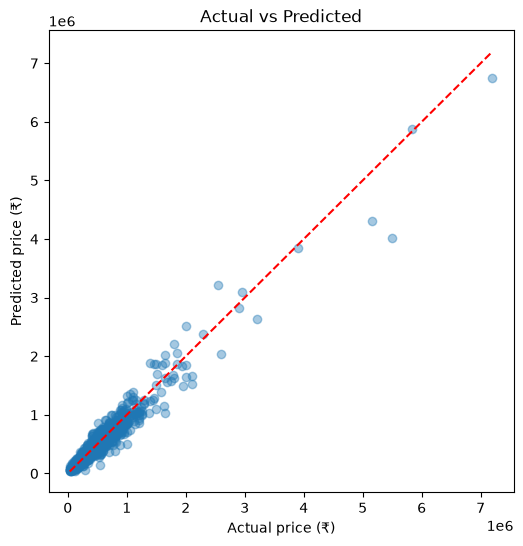

In [11]:
import matplotlib.pyplot as plt

best_model = gb   # change to rf or lr if the table shows another model is best

y_true = np.expm1(y_test)
y_pred = np.expm1(best_model.predict(X_test))

plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.4)
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], "r--")
plt.xlabel("Actual price (₹)")
plt.ylabel("Predicted price (₹)")
plt.title("Actual vs Predicted")
plt.show()

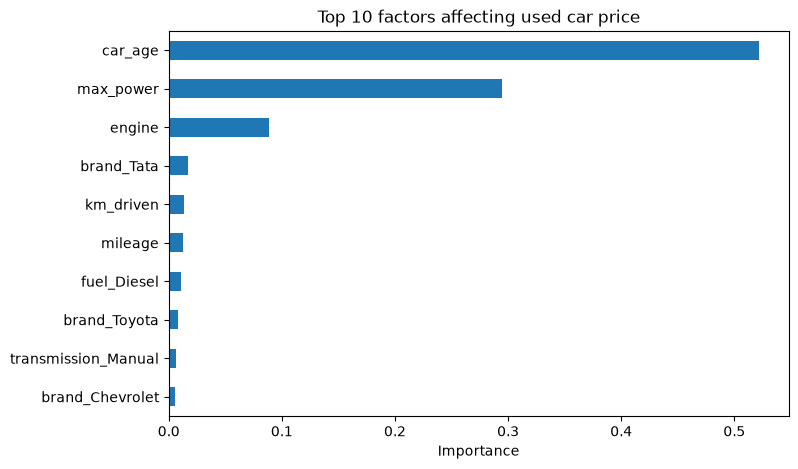

car_age                0.522001
max_power              0.294657
engine                 0.088977
brand_Tata             0.017460
km_driven              0.013316
mileage                0.012558
fuel_Diesel            0.010772
brand_Toyota           0.007980
transmission_Manual    0.006813
brand_Chevrolet        0.005207
dtype: float64

In [12]:
import matplotlib.pyplot as plt

best_model = gb   # change to rf if Random Forest scored better

importances = pd.Series(best_model.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)

top10.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 factors affecting used car price")
plt.xlabel("Importance")
plt.show()

top10

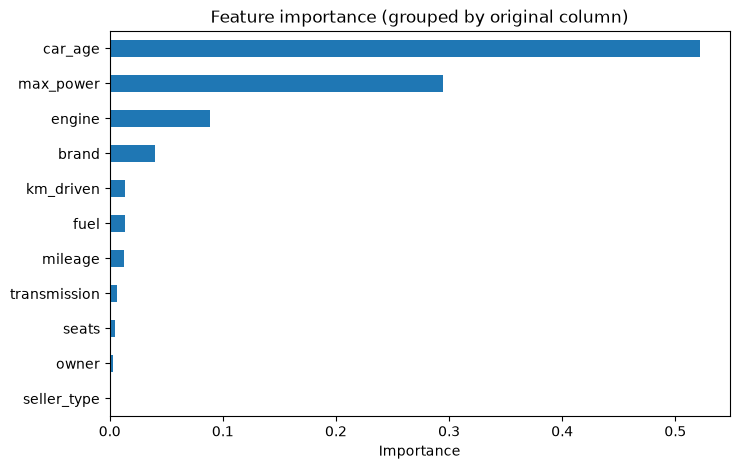

car_age         0.522001
max_power       0.294657
engine          0.088977
brand           0.040192
km_driven       0.013316
fuel            0.013166
mileage         0.012558
transmission    0.006813
seats           0.004729
owner           0.003005
seller_type     0.000587
dtype: float64

In [13]:
def original_feature(col):
    for prefix in ["fuel", "seller_type", "transmission", "owner", "brand"]:
        if col.startswith(prefix + "_"):
            return prefix
    return col

grouped = importances.groupby(original_feature).sum().sort_values()

grouped.plot(kind="barh", figsize=(8, 5))
plt.title("Feature importance (grouped by original column)")
plt.xlabel("Importance")
plt.show()

grouped.sort_values(ascending=False)

In [14]:
grouped.sort_values(ascending=False).to_csv("data/feature_importance.csv", header=["importance"])

In [17]:
import joblib

joblib.dump(best_model, "car_price_model.pkl", compress=3)

['car_price_model.pkl']

In [18]:
meta = {
    "columns": list(X.columns),                              # exact column order used in training
    "brands": sorted(df["brand"].unique().tolist()),
    "fuels": sorted(df["fuel"].unique().tolist()),
    "seller_types": sorted(df["seller_type"].unique().tolist()),
    "transmissions": sorted(df["transmission"].unique().tolist()),
    "owners": sorted(df["owner"].unique().tolist()),
    "seats": sorted(df["seats"].unique().tolist()),
    "defaults": {                                            # starting values for the form
        "km_driven": int(df["km_driven"].median()),
        "mileage": float(df["mileage"].median()),
        "engine": float(df["engine"].median()),
        "max_power": float(df["max_power"].median()),
    },
}

joblib.dump(meta, "model_meta.pkl")

['model_meta.pkl']

In [19]:
results.to_csv("data/model_results.csv", index=False)

In [20]:
model = joblib.load("car_price_model.pkl")
meta = joblib.load("model_meta.pkl")

# one sample car
sample = pd.DataFrame([{
    "km_driven": 60000, "mileage": 20.0, "engine": 1197, "max_power": 82.0,
    "seats": 5.0, "car_age": 5,
    "fuel": "Petrol", "seller_type": "Individual",
    "transmission": "Manual", "owner": "First Owner", "brand": "Maruti",
}])

sample = pd.get_dummies(sample)
sample = sample.reindex(columns=meta["columns"], fill_value=0)   # match training columns

pred = np.expm1(model.predict(sample))[0]
print(f"Predicted price: ₹{pred:,.0f}")

Predicted price: ₹485,163
